In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
np.random.seed(42)

n = 100

df = pd.DataFrame({
    "Customer_ID": range(1, n + 1),
    "Age": np.random.randint(18, 66, n),
    "Location": np.random.choice(
        ["Bengaluru", "Mysuru", "Mangaluru", "Hubballi"],
        n
    ),
    "Annual_Income": np.random.randint(20000, 120001, n),
    "Purchases": np.random.randint(1, 31, n),
    "Total_Spending": np.random.randint(500, 50001, n)
})

df.head()

,Customer_ID,Age,Location,Annual_Income,Purchases,Total_Spending
0,1,56,Hubballi,35707,16,40947
1,2,46,Hubballi,41976,26,8708
2,3,32,Hubballi,64262,16,19089
3,4,60,Mangaluru,43776,25,43984
4,5,25,Mangaluru,50080,20,17953


In [3]:
print("Dataset shape:", df.shape)

print("\nColumn information:")
df.info()

print("\nStatistical summary:")
display(df.describe())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate records:", df.duplicated().sum())

Dataset shape: (100, 6)

Column information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 6 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   Customer_ID     100 non-null    int64 
 1   Age             100 non-null    int64 
 2   Location        100 non-null    object
 3   Annual_Income   100 non-null    int64 
 4   Purchases       100 non-null    int64 
 5   Total_Spending  100 non-null    int64 
dtypes: int64(5), object(1)
memory usage: 4.8+ KB

Statistical summary:


,Customer_ID,Age,Annual_Income,Purchases,Total_Spending
count,100.000000,100.000000,100.000000,100.000000,100.000000
mean,50.500000,40.920000,72158.310000,15.180000,24004.330000
std,29.011492,14.054497,29862.871648,9.287093,14737.888902
min,1.000000,18.000000,20854.000000,1.000000,690.000000
25%,25.750000,30.500000,45302.500000,6.000000,11208.500000
50%,50.500000,41.000000,72697.500000,16.000000,23385.000000
75%,75.250000,53.250000,101270.000000,22.250000,36385.750000
max,100.000000,65.000000,118506.000000,30.000000,49656.000000



Missing values:
Customer_ID       0
Age               0
Location          0
Annual_Income     0
Purchases         0
Total_Spending    0
dtype: int64

Duplicate records: 0


In [4]:
df["Age_Group"] = pd.cut(
    df["Age"],
    bins=[17, 25, 35, 50, 65],
    labels=["18-25", "26-35", "36-50", "51-65"]
)

age_analysis = df.groupby(
    "Age_Group", observed=False
).agg(
    Customers=("Customer_ID", "count"),
    Average_Spending=("Total_Spending", "mean"),
    Total_Revenue=("Total_Spending", "sum")
)

display(age_analysis.round(2))

,Customers,Average_Spending,Total_Revenue
Age_Group,,,
18-25,18,21098.89,379780
26-35,21,23043.10,483905
36-50,31,24785.94,768364
51-65,30,25612.80,768384


In [5]:
location_analysis = df.groupby("Location").agg(
    Customers=("Customer_ID", "count"),
    Total_Revenue=("Total_Spending", "sum"),
    Average_Spending=("Total_Spending", "mean"),
    Average_Purchases=("Purchases", "mean")
)

display(location_analysis.round(2))

,Customers,Total_Revenue,Average_Spending,Average_Purchases
Location,,,,
Bengaluru,22,512532,23296.91,15.86
Hubballi,25,579622,23184.88,15.40
Mangaluru,34,859668,25284.35,15.76
Mysuru,19,448611,23611.11,13.05


In [6]:
df["Spending_Group"] = pd.cut(
    df["Total_Spending"],
    bins=[0, 10000, 25000, float("inf")],
    labels=["Low Spenders", "Medium Spenders", "High Spenders"]
)

spending_analysis = df.groupby(
    "Spending_Group", observed=False
).agg(
    Customers=("Customer_ID", "count"),
    Total_Revenue=("Total_Spending", "sum"),
    Average_Spending=("Total_Spending", "mean")
)

display(spending_analysis.round(2))

,Customers,Total_Revenue,Average_Spending
Spending_Group,,,
Low Spenders,23,106460,4628.70
Medium Spenders,30,522112,17403.73
High Spenders,47,1771861,37699.17


In [7]:
print("Top 10 customers by spending:")

top_customers = df.sort_values(
    "Total_Spending", ascending=False
)

display(top_customers.head(10))

print("Highest-revenue age group:")
display(age_analysis.sort_values(
    "Total_Revenue", ascending=False
).head(1))

print("Highest-revenue location:")
display(location_analysis.sort_values(
    "Total_Revenue", ascending=False
).head(1))

Top 10 customers by spending:


,Customer_ID,Age,Location,Annual_Income,Purchases,Total_Spending,Age_Group,Spending_Group
85,86,64,Mysuru,91295,2,49656,51-65,High Spenders
84,85,35,Bengaluru,103879,27,49247,26-35,High Spenders
80,81,57,Mysuru,87270,19,48596,51-65,High Spenders
7,8,36,Hubballi,26776,2,47702,36-50,High Spenders
99,100,18,Mangaluru,66843,17,46685,18-25,High Spenders
29,30,44,Bengaluru,59353,20,46181,36-50,High Spenders
14,15,41,Mangaluru,114856,27,45736,36-50,High Spenders
55,56,64,Hubballi,32688,1,45591,51-65,High Spenders
38,39,24,Bengaluru,113264,3,45517,18-25,High Spenders
6,7,56,Bengaluru,81373,17,44025,51-65,High Spenders


Highest-revenue age group:


,Customers,Average_Spending,Total_Revenue
Age_Group,,,
51-65,30,25612.8,768384


Highest-revenue location:


,Customers,Total_Revenue,Average_Spending,Average_Purchases
Location,,,,
Mangaluru,34,859668,25284.352941,15.764706


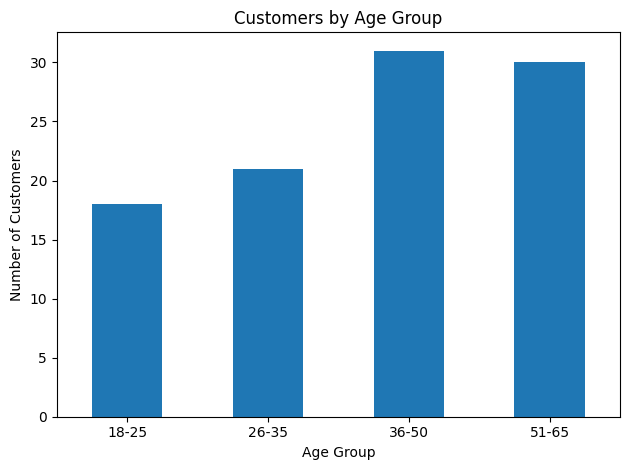

In [8]:
df["Age_Group"].value_counts(
    sort=False
).plot(kind="bar", title="Customers by Age Group")

plt.xlabel("Age Group")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

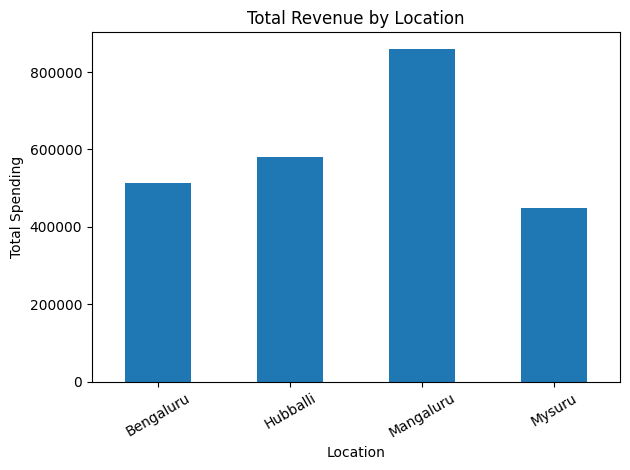

In [9]:
location_analysis["Total_Revenue"].plot(
    kind="bar",
    title="Total Revenue by Location"
)

plt.xlabel("Location")
plt.ylabel("Total Spending")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

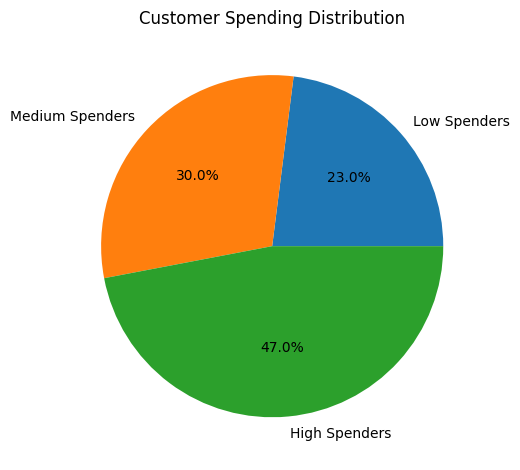

In [10]:
df["Spending_Group"].value_counts(
    sort=False
).plot(
    kind="pie",
    autopct="%1.1f%%",
    title="Customer Spending Distribution"
)

plt.ylabel("")
plt.tight_layout()
plt.show()

In [11]:
df.to_csv(
    "customer_segmentation_results.csv",
    index=False
)

print("Customer analysis completed successfully!")
print("File saved: customer_segmentation_results.csv")

Customer analysis completed successfully!
File saved: customer_segmentation_results.csv


In [12]:
df.to_csv(
    "customer_segmentation_results.csv",
    index=False
)

print("Customer analysis completed successfully!")
print("File saved: customer_segmentation_results.csv")

Customer analysis completed successfully!
File saved: customer_segmentation_results.csv
